# Contextual Alertness
**FINM 36700 · Portfolio and Risk Management · Midterm Project, Autumn 2026**

**HW Group B:** Avi Rastogi, Lucas Albin Lazcano, Mengting Wang, Siena Verprauskus

## Setup

- Data: `data/project_situational_awareness_20261026.xlsx`, daily simple total returns, 2021-01-04 to 2026-10-26.
- `returns` stops at the end of the design window (July 31, 2026). The holdout is only opened in 6.3.
- The 4x book is the daily-reset book: constant weights of ±1/3. Its weights sum to zero, so its return is already an excess return. The 1x book is the 4x book divided by four.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, binomtest

DATA = Path('../data/project_situational_awareness_20261026.xlsx')

returns_all = pd.read_excel(DATA, sheet_name='total returns', index_col='Date', parse_dates=True)
weights = pd.read_excel(DATA, sheet_name='baseline weights').set_index('ticker')['equal-sleeve weight']

NAMES = weights.index.tolist()
LONGS = weights[weights > 0].index.tolist()
SHORTS = weights[weights < 0].index.tolist()

# design window only; the holdout (Aug 3 - Oct 26, 2026) is used in 6.3 and nowhere else
returns = returns_all.loc[:'2026-07-31']

FULL = slice('2021-01-04', '2026-06-30')
RECENT = slice('2025-01-02', '2026-06-30')
PRE = slice('2021-01-04', '2024-12-31')
REPORT = slice('2025-01-02', '2026-07-31')
REVERSAL = slice('2026-07-24', '2026-07-29')

book_4x = returns[NAMES] @ weights
book_1x = book_4x / 4

plt.rcParams.update({'figure.figsize': (10, 3.5), 'axes.spines.top': False, 'axes.spines.right': False})
print(f'{len(returns)} days in the design window, {returns.index[0].date()} to {returns.index[-1].date()}')

1400 days in the design window, 2021-01-04 to 2026-07-31


---
# 1. The Book as Given

## 1.1

> Verify the long, short, gross and net exposures as multiples of NAV and as dollars on $100 million of NAV. Then, for the 4x book and the 1x book, report over 2021-01-04 to 2026-06-30 and over 2025-01-02 to 2026-06-30:
> 
> - annualized mean and volatility, Sharpe ratio, skewness, excess kurtosis
> - worst day, empirical 5% VaR and CVaR
> - maximum drawdown with its peak and trough dates, and cumulative return
> 
> Group the statistics by how they respond to leverage. Explain the scaling and compounding within each group.

In [2]:
exposure = pd.DataFrame({'x NAV (4x book)': [weights[LONGS].sum(), weights[SHORTS].sum(),
                                             weights.abs().sum(), weights.sum()]},
                        index=['long', 'short', 'gross', 'net'])
exposure['x NAV (1x book)'] = exposure['x NAV (4x book)'] / 4
exposure['$mm (4x book)'] = exposure['x NAV (4x book)'] * 100
exposure['$mm (1x book)'] = exposure['x NAV (1x book)'] * 100
exposure.round(2) + 0.0

,x NAV (4x book),x NAV (1x book),$mm (4x book),$mm (1x book)
long,2.0,0.5,200.0,50.0
short,-2.0,-0.5,-200.0,-50.0
gross,4.0,1.0,400.0,100.0
net,0.0,0.0,0.0,0.0


The exposures check out. 4x book: +200% (+$200M) long, -200% (-$200M) short, 400% ($400M) gross, 0% ($0M) net. 1x book: ±50% (±$50M) per side, 100% ($100M) gross, 0% net.

In [3]:
def summary_stats(r):
    wealth = (1 + r).cumprod()
    drawdown = wealth / wealth.cummax() - 1
    trough = drawdown.idxmin()
    peak = wealth.loc[:trough].idxmax()
    q05 = r.quantile(0.05)
    return pd.Series({
        'ann. mean': r.mean() * 252,
        'ann. vol': r.std() * np.sqrt(252),
        'Sharpe': r.mean() / r.std() * np.sqrt(252),
        'skewness': r.skew(),
        'excess kurtosis': r.kurt(),
        'worst day': r.min(),
        'VaR 5%': -q05,
        'CVaR 5%': -r[r <= q05].mean(),
        'max drawdown': drawdown.min(),
        'peak date': peak.date(),
        'trough date': trough.date(),
        'cumulative return': wealth.iloc[-1] - 1,
    })

table_1_1 = pd.DataFrame({
    '4x, 2021-26H1': summary_stats(book_4x.loc[FULL]),
    '1x, 2021-26H1': summary_stats(book_1x.loc[FULL]),
    '4x, 2025-26H1': summary_stats(book_4x.loc[RECENT]),
    '1x, 2025-26H1': summary_stats(book_1x.loc[RECENT]),
})

pct = ['ann. mean', 'ann. vol', 'worst day', 'VaR 5%', 'CVaR 5%', 'max drawdown', 'cumulative return']
num = ['Sharpe', 'skewness', 'excess kurtosis']
table_1_1.style.format('{:.2%}', subset=(pct, table_1_1.columns)).format('{:.2f}', subset=(num, table_1_1.columns))

,"4x, 2021-26H1","1x, 2021-26H1","4x, 2025-26H1","1x, 2025-26H1"
ann. mean,124.72%,31.18%,424.81%,106.20%
ann. vol,89.87%,22.47%,136.64%,34.16%
Sharpe,1.39,1.39,3.11,3.11
skewness,0.07,0.07,-0.34,-0.34
excess kurtosis,4.64,4.64,1.80,1.80
worst day,-35.96%,-8.99%,-35.96%,-8.99%
VaR 5%,7.32%,1.83%,13.63%,3.41%
CVaR 5%,12.35%,3.09%,19.75%,4.94%
max drawdown,-79.38%,-26.26%,-48.44%,-13.57%
peak date,2021-01-19,2021-01-19,2026-05-13,2026-05-13


In [4]:
# how each statistic responds to leverage: 4x value / 1x value
stats_num = table_1_1.drop(['peak date', 'trough date']).astype(float)
leverage_ratio = pd.DataFrame({
    '2021-26H1': stats_num['4x, 2021-26H1'] / stats_num['1x, 2021-26H1'],
    '2025-26H1': stats_num['4x, 2025-26H1'] / stats_num['1x, 2025-26H1'],
})
leverage_ratio.round(2).rename(columns=lambda c: f'4x / 1x, {c}')

,"4x / 1x, 2021-26H1","4x / 1x, 2025-26H1"
ann. mean,4.00,4.00
ann. vol,4.00,4.00
Sharpe,1.00,1.00
skewness,1.00,1.00
excess kurtosis,1.00,1.00
worst day,4.00,4.00
VaR 5%,4.00,4.00
CVaR 5%,4.00,4.00
max drawdown,3.02,3.57
cumulative return,25.88,37.27


**Answer 1.1.**

_Scaled metrics_:

Annual mean, annual volatility, worst day, and empirical VaR and CVaR all scale linearly with leverage. This is because they all depend on the size of each day's return, and all daily returns are scaled by 4x with leverage.

_Constant metrics_:

Sharpe, skewness and excess kurtosis remain equal across leverage levels. Sharpe remains the same because leverage amplifies returns but equally amplifies volatility. Skewness and excess kurtosis are unaffected by scaling, since they are standardized moments.

_Non-linear metrics_:

Maximum drawdown and cumulative return are non-linear in leverage because they are measured on the compounded path. Losses compound on a shrinking NAV, so max drawdown scales by 3.0× rather than 4× (−26% to −79% over 2021-2026). Gains compound on a growing NAV, so cumulative return rises 26× over 2021–2026 and 37× over 2025–2026.

## 1.2

> Report the compounded calendar-year return of the 4x book for 2021 through 2026 (to July 31), with the contribution of each sleeve, defined as the sum of the sleeve's daily weighted returns. The sleeve contributions add to the sum of the book's daily returns rather than to its compounded year; report both. In which years did the short sleeve add to the return, and in which did it subtract?

In [5]:
long_sleeve = returns[LONGS] @ weights[LONGS]
short_sleeve = returns[SHORTS] @ weights[SHORTS]
year = book_4x.index.year

table_1_2 = pd.DataFrame({
    'compounded return': book_4x.groupby(year).apply(lambda r: (1 + r).prod() - 1),
    'sum of daily returns': book_4x.groupby(year).sum(),
    'long sleeve': long_sleeve.groupby(year).sum(),
    'short sleeve': short_sleeve.groupby(year).sum(),
})
table_1_2.index = [str(y) for y in table_1_2.index[:-1]] + ['2026 (to Jul 31)']
table_1_2.style.format('{:+.1%}')

,compounded return,sum of daily returns,long sleeve,short sleeve
2021,-28.9%,-19.4%,+36.6%,-55.9%
2022,-20.7%,-3.8%,-79.1%,+75.3%
2023,-34.8%,-25.1%,+100.5%,-125.6%
2024,+110.6%,+101.5%,+123.5%,-22.0%
2025,+795.5%,+274.6%,+288.8%,-14.2%
2026 (to Jul 31),+325.8%,+267.5%,+223.7%,+43.9%


**Answer 1.2.**

The short sleeve added to the sum of daily returns in years 2022 (+75%) and 2026 (+44%, to July 31), while it subtracted in years 2021 (-56%), 2023 (-126%), 2024 (-22%), and 2025 (-14%). The only year in which the short sleeve hedged against losses in the long sleeve was in 2022 (+75%), when compensated by a sum of daily returns of -79% from the long sleeve. 


## 1.3

> Over both windows in 1.1, report
> 
> - the average pairwise correlation among the long names, among the short names, and between a long and a short name
> - the correlation between the long basket's return and the short basket's return
> 
> What, if anything, does the short sleeve hedge?

In [6]:
def avg_corr(c, rows, cols):
    block = c.loc[rows, cols].values
    if rows == cols:
        block = block[np.triu_indices_from(block, k=1)]   # distinct pairs only
    return block.mean()

def corr_stats(r):
    c = r[NAMES].corr()
    long_basket = r[LONGS].mean(axis=1)
    short_basket = r[SHORTS].mean(axis=1)
    return pd.Series({
        'avg corr, long-long': avg_corr(c, LONGS, LONGS),
        'avg corr, short-short': avg_corr(c, SHORTS, SHORTS),
        'avg corr, long-short': avg_corr(c, LONGS, SHORTS),
        'corr, long basket vs short basket': long_basket.corr(short_basket),
    })

pd.DataFrame({'2021-26H1': corr_stats(returns.loc[FULL]),
              '2025-26H1': corr_stats(returns.loc[RECENT])}).round(2)

,2021-26H1,2025-26H1
"avg corr, long-long",0.48,0.55
"avg corr, short-short",0.50,0.50
"avg corr, long-short",0.24,0.11
"corr, long basket vs short basket",0.43,0.23


**Answer 1.3.**

Names move together within the sleeves (avg. correlation of about 0.5), but the correlation across sleeves is weak (0.24 among names and 0.43 between the baskets over the full sample) and weakening (0.11 and 0.23 in the last 18 months). The short therefore only hedges the small market exposure the two sides share and none of the hardware theme. Rather than a hedge, it is a second bet as part of the thesis of the trade.

## 1.4

> For each window in 1.1, report the standard error of the 4x book's annualized mean and of its Sharpe ratio, and the Sharpe ratio's 95% band. You are reviewing the book on June 30, 2026 with the statistics from 1.1 to 1.4 in hand. Which window would you base a risk assessment on, and what is a Sharpe ratio estimated on eighteen months of daily data evidence of? Answer in a short paragraph that uses the standard errors.
> 
> *Estimation error:* under independence, the standard error of an annualized mean estimated from $N$ years of daily data is $\sigma_{\text{ann}}/\sqrt{N}$. With $q = 252$ periods a year, the annualized Sharpe ratio has standard error $\sqrt{(1 + \text{SR}^2/2q)/N}$.

In [7]:
def estimation_error(r):
    years = len(r) / 252
    mean = r.mean() * 252
    vol = r.std() * np.sqrt(252)
    sharpe = mean / vol
    se_sharpe = np.sqrt((1 + sharpe**2 / (2 * 252)) / years)
    return pd.Series({
        'years (N)': years,
        'ann. mean': mean,
        'SE of mean': vol / np.sqrt(years),
        'Sharpe': sharpe,
        'SE of Sharpe': se_sharpe,
        'Sharpe 95% low': sharpe - 1.96 * se_sharpe,
        'Sharpe 95% high': sharpe + 1.96 * se_sharpe,
    })

pd.DataFrame({'4x, 2021-26H1': estimation_error(book_4x.loc[FULL]),
              '4x, 2025-26H1': estimation_error(book_4x.loc[RECENT])}).round(2)

,"4x, 2021-26H1","4x, 2025-26H1"
years (N),5.47,1.48
ann. mean,1.25,4.25
SE of mean,0.38,1.12
Sharpe,1.39,3.11
SE of Sharpe,0.43,0.83
Sharpe 95% low,0.55,1.48
Sharpe 95% high,2.23,4.74


**Answer 1.4.**

We would base our risk assessment on the full sample window, as it covers more years (5.5 vs. 1.5), so its standard error is about 3x smaller for the mean (38% vs 112%) and about half as large for the Sharpe (0.43 vs 0.83). It also includes a losing regime (2021 to 2023), while the recent sample and its Sharpe estimate simply reflect strong performance in hardware over one regime, not a good estimate of the expected Sharpe in the future. Finally, 18 months of daily data sounds like a lot, but it is really just 1.5 years in annual terms, making the standard error too large (95% band of 1.48 to 4.74) for any conclusion about whether the returns came from skill or from the theme.

---
# 2. The Reset

## 2.1

> Start on 2025-01-02 with $100 million of NAV and positions set to the 4x target weights at the prior close. Hold cash as collateral without interest. Compare three rules:
> 
> - Reset to target weights at every close.
> - Reset at every month-end close.
> - Hold the initial shares without rebalancing.
> 
> Gross exposure is measured at each close for the following day. Report:
> 
> - NAV and gross leverage through July 31, 2026, as plots.
> - For each rule: gross exposure set on June 22 and July 23, NAV relative to its initial value on June 22, the July 24 to 29 return, and whether and when NAV reaches zero.
> - For fixed shares initialized on 2021-01-04: maximum gross exposure and minimum NAV, with their dates.
> - For fixed shares initialized at the July 23, 2026 close to the 4x target on $100 million: NAV, long exposure, short exposure, and gross leverage at each of the four closes through July 29. Compare NAV with the daily-reset portfolio over the same four days.
> 
> Could a fund have maintained each path? Use the gross exposures and NAV paths to explain what daily resetting assumes about the fund as a going concern, which convention a real fund lives under, and why the same positions lose different fractions of NAV over the reversal.

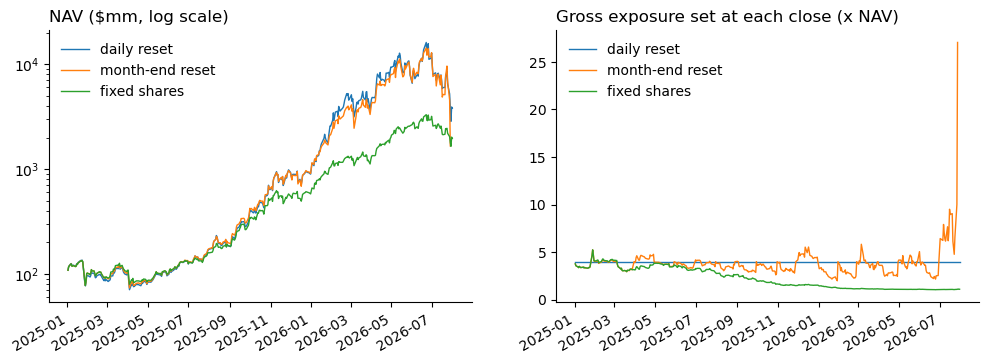

In [8]:
def simulate(rets, rebalance_dates, nav0=100.0):
    """Dollar book in $mm. Positions start at the 4x target, set at the close before the first day.
    Cash earns nothing. On a rebalance date the positions are reset to the target at that close.
    Exposures are recorded after the close, i.e. the exposure held into the next day."""
    pos = weights * nav0
    cash = nav0 - pos.sum()
    rows = []
    for date, r in rets.iterrows():
        pos = pos * (1 + r)
        nav = cash + pos.sum()
        if nav <= 0:                                   # the book is wiped out: stop here
            rows.append({'date': date, 'NAV': nav})
            break
        if date in rebalance_dates:
            pos = weights * nav
            cash = nav - pos.sum()
        rows.append({'date': date, 'NAV': nav,
                     'long': pos[LONGS].sum() / nav, 'short': pos[SHORTS].sum() / nav,
                     'gross': pos.abs().sum() / nav})
    return pd.DataFrame(rows).set_index('date')

rets_2025 = returns.loc[REPORT, NAMES]
month_ends = set(rets_2025.index.to_series().groupby(rets_2025.index.to_period('M')).max())

paths = {
    'daily reset': simulate(rets_2025, set(rets_2025.index)),
    'month-end reset': simulate(rets_2025, month_ends),
    'fixed shares': simulate(rets_2025, set()),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, p in paths.items():
    p['NAV'].where(p['NAV'] > 0).plot(ax=axes[0], label=name, lw=1)
    p['gross'].plot(ax=axes[1], label=name, lw=1)
axes[0].set_yscale('log'); axes[0].set_title('NAV ($mm, log scale)', loc='left')
axes[1].set_title('Gross exposure set at each close (x NAV)', loc='left')
for ax in axes:
    ax.set_xlabel(''); ax.legend(frameon=False)
plt.show()

In [9]:
summary_2_1 = {}
for name, p in paths.items():
    zero = p.index[p['NAV'] <= 0]
    summary_2_1[name] = {
        'gross at Jun 22': p.loc['2026-06-22', 'gross'],
        'gross at Jul 23': p.loc['2026-07-23', 'gross'],
        'NAV / initial, Jun 22': p.loc['2026-06-22', 'NAV'] / 100,
        'Jul 24-29 return': p.loc['2026-07-29', 'NAV'] / p.loc['2026-07-23', 'NAV'] - 1,
        'NAV reaches zero': zero[0].date() if len(zero) else 'no',
    }
pd.DataFrame(summary_2_1).T.style.format({'gross at Jun 22': '{:.2f}x', 'gross at Jul 23': '{:.2f}x',
                                         'NAV / initial, Jun 22': '{:.1f}x', 'Jul 24-29 return': '{:.1%}'})

,gross at Jun 22,gross at Jul 23,"NAV / initial, Jun 22",Jul 24-29 return,NAV reaches zero
daily reset,4.00x,4.00x,161.3x,-66.9%,no
month-end reset,2.22x,4.77x,142.7x,-110.2%,2026-07-29
fixed shares,1.05x,1.07x,33.0x,-32.7%,no


In [10]:
# fixed shares initialized on 2021-01-04 (positions set at the Dec 31, 2020 close)
fixed_2021 = simulate(returns.loc['2021-01-04':, NAMES], set())
pd.Series({
    'max gross (x NAV)': round(fixed_2021['gross'].max(), 1),
    'date of max gross': fixed_2021['gross'].idxmax().date(),
    'min NAV ($mm)': round(fixed_2021['NAV'].min(), 1),
    'date of min NAV': fixed_2021['NAV'].idxmin().date(),
}).to_frame('fixed shares from 2021-01-04')

,fixed shares from 2021-01-04
max gross (x NAV),22.1
date of max gross,2021-10-22
min NAV ($mm),18.5
date of min NAV,2023-07-19


In [11]:
# fixed shares initialized at the July 23, 2026 close, vs the daily-reset book over the same four days
fixed_jul = simulate(returns.loc[REVERSAL, NAMES], set())
table_2_1 = pd.DataFrame({
    'fixed shares NAV ($mm)': fixed_jul['NAV'],
    'long (x NAV)': fixed_jul['long'],
    'short (x NAV)': fixed_jul['short'],
    'gross (x NAV)': fixed_jul['gross'],
    'daily reset NAV ($mm)': 100 * (1 + book_4x.loc[REVERSAL]).cumprod(),
})
table_2_1.index = table_2_1.index.date
table_2_1.round(2)

,fixed shares NAV ($mm),long (x NAV),short (x NAV),gross (x NAV),daily reset NAV ($mm)
2026-07-24,75.11,2.42,-2.75,5.16,75.11
2026-07-27,55.74,3.13,-3.92,7.06,60.40
2026-07-28,30.06,5.24,-7.56,12.80,43.85
2026-07-29,7.55,18.96,-31.20,50.17,33.09


In [12]:
#daily resets as a % of NAV on average and on reversal
drifted = (returns[NAMES] * weights).add(weights).div(1 + book_4x, axis=0)
turnover = (drifted - weights).abs().sum(axis=1)

print(f'average daily turnover, report window: {turnover.loc[REPORT].mean():.0%} of NAV')
turnover.loc[REVERSAL].to_frame('turnover (x NAV)').set_axis(turnover.loc[REVERSAL].index.date).style.format('{:.0%}')

average daily turnover, report window: 25% of NAV


,turnover (x NAV)
2026-07-24,116%
2026-07-27,103%
2026-07-28,134%
2026-07-29,116%


**Answer 2.1.**

  _Could a fund maintain each path?:_

Theoretically, the daily reset and the fixed shares strategy could be sustained by a fund, as neither would "blow up" (NAV going to zero) as the monthly reset portfolio did. However, the fixed shares portfolio would not comply with the fund's mandate of being long 2x hardware and short 2x software.

  _Daily resetting as a going concern:_

  Daily resetting implies being able to trade the whole book at close for free and at any size, which is not realistic. Indeed, daily resets would be on average around 25% of NAV and above 100% during the reversal. 

_Which convention a real fund lives under:_

A real fund would be similar to the fixed shares convention between trades. Leverage would increase if the trade performs poorly and decrease if it performs well, and it would only be adjusted whenever the risk manager sees fit or when a prime broker issues a margin call. 

_Why the same positions lose different fractions of NAV over the reversal:_

The difference is mainly due to gross exposure: the fixed shares portfolio came into the reversal at 1.07x leverage, daily reset at 4x, and monthly reset at 4.8x (losing 33%, 67% and 110% respectively). As NAV fell, closing leverage increased for the fixed and monthly reset portfolios, further increasing opening leverage on the next day and amplifying losses even further. By rebalancing daily, the daily reset portfolio "survived" this leverage-loss spiral, albeit through significant rebalancing costs if we consider transaction costs.

---
# 3. One-Day VaR Through the Reversal

## 3.1

> Compute the EWMA volatility forecast of the 4x book from the first day your initialization allows to July 31, 2026, and, for every day in the design window, three one-day 5% VaR forecasts and the CVaR of each: historical simulation, Normal EWMA and filtered historical simulation.
> 
> - Plot the EWMA forecast annualized; report the forecast made for July 24, 2026 and the fraction of forecasts for days through June 30, 2026 that were lower.
> - Report the three VaR and CVaR forecasts made at the July 23, 2026 close.
> 
> *VaR conventions:* Historical simulation: minus the 5% quantile of the trailing 252 daily returns; the CVaR is minus the mean of the returns at or below that quantile. Normal EWMA: $\text{VaR}_t = -z_{0.05}\,\sigma_t$ and $\text{CVaR}_t = \sigma_t\,\phi(z_{0.05})/0.05$, with $\sigma_t$ the EWMA forecast. Filtered historical simulation: standardize each past return by the EWMA forecast that applied to it, $z_s = r_s/\sigma_s$; take the 5% quantile and the tail mean of the standardized returns over the trailing 252 days, the same window as the historical simulation; multiply both by the current forecast $\sigma_t$.

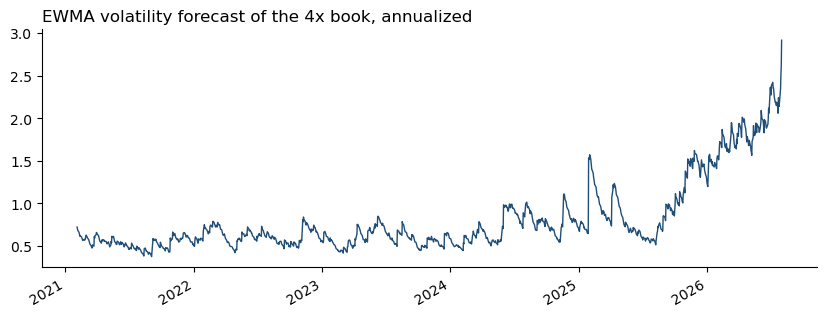

first EWMA forecast: 2021-02-03
forecast for Jul 24, 2026: 213.9% annualized (13.48% daily)
share of forecasts through Jun 30, 2026 that were lower: 99.9%


In [13]:
LAMBDA, INIT_DAYS, WINDOW = 0.94, 21, 252
Z05 = norm.ppf(0.05)
METHODS = ['HS', 'EWMA', 'FHS']

def ewma_vol(r):
    """sigma[t] = EWMA forecast for day t, using returns through day t-1."""
    x = r.values
    var = np.full(len(x), np.nan)
    var[INIT_DAYS] = np.mean(x[:INIT_DAYS] ** 2)
    for t in range(INIT_DAYS + 1, len(x)):
        var[t] = LAMBDA * var[t - 1] + (1 - LAMBDA) * x[t - 1] ** 2
    return pd.Series(np.sqrt(var), index=r.index)

def var_cvar(x, alpha=0.05):
    q = np.quantile(x, alpha)
    return -q, -x[x <= q].mean()

def var_forecasts(r, window=WINDOW):
    sigma = ewma_vol(r)
    z = (r / sigma).values
    out = pd.DataFrame(index=r.index, columns=['sigma'] + [f'{m} {s}' for m in METHODS for s in ['VaR', 'CVaR']],
                       dtype=float)
    out['sigma'] = sigma
    out['EWMA VaR'] = -Z05 * sigma
    out['EWMA CVaR'] = sigma * norm.pdf(Z05) / 0.05
    for t in range(window, len(r)):
        out.iloc[t, out.columns.get_indexer(['HS VaR', 'HS CVaR'])] = var_cvar(r.values[t - window:t])
        past_z = z[t - window:t]
        if not np.isnan(past_z).any():
            z_var, z_cvar = var_cvar(past_z)
            out.iloc[t, out.columns.get_indexer(['FHS VaR', 'FHS CVaR'])] = z_var * sigma.iloc[t], z_cvar * sigma.iloc[t]
    return out

fc = var_forecasts(book_4x)
ewma_ann = fc['sigma'] * np.sqrt(252)

ewma_ann.plot(color='#1f4e79', lw=1)
plt.title('EWMA volatility forecast of the 4x book, annualized', loc='left'); plt.xlabel('')
plt.show()

jul24 = ewma_ann.loc['2026-07-24']
print(f'first EWMA forecast: {ewma_ann.first_valid_index().date()}')
print(f'forecast for Jul 24, 2026: {jul24:.1%} annualized ({fc.loc["2026-07-24", "sigma"]:.2%} daily)')
print(f'share of forecasts through Jun 30, 2026 that were lower: {(ewma_ann.loc[:"2026-06-30"].dropna() < jul24).mean():.1%}')

In [14]:
made_jul23 = fc.loc['2026-07-24']          # forecast for July 24, made at the July 23 close
pd.DataFrame({'VaR': [made_jul23[f'{m} VaR'] for m in METHODS],
              'CVaR': [made_jul23[f'{m} CVaR'] for m in METHODS]},
             index=METHODS).style.format('{:.1%}')

,VaR,CVaR
HS,16.6%,20.9%
EWMA,22.2%,27.8%
FHS,21.3%,27.3%


In [15]:
ewma_ann.loc[:'2026-06-30'].nlargest(7)

Date
2026-06-29    2.363287
2026-06-30    2.292826
2026-06-26    2.138206
2026-06-24    2.116850
2026-06-03    2.091038
2026-06-25    2.059855
2026-06-04    2.045084
Name: sigma, dtype: float64

**Answer 3.1.**

_Initialization:_

We set the starting σ² to the zero-mean sample variance (mean squared return) of the first 21 trading days, so the first forecast is for 2021-02-03. With λ = 0.94, the weight of the seed falls below 2% after three months, so the estimates after 2021 do not depend on it.

_Forecast:_

The EWMA forecast for July 24 was 214% annualized (13.5% daily), higher than 99.9% of all forecasts through June 30. At the July 23 close, Normal EWMA gave a VaR/CVaR of 22.2%/27.8% and FHS a nearly identical 21.3%/27.3%, since both scale to the current EWMA volatility estimate. Historical simulation was the lowest at 16.6%/20.9%, as its 252-day window still lags rise in volatility leading to the reversal.



## 3.2

> Backtest the three methods over 2025-01-02 to 2026-07-23 and over 2021-01-04 to 2024-12-31. For each method and window report
> 
> - the number of forecasts, the number of breaches and the hit ratio
> - the longest run of consecutive breaches
> - the mean realized loss on breach days beside the mean CVaR forecast on those days
> 
> A method whose window has not yet filled starts later; report its count and say so. Which methods are calibrated in each window, and where the hit ratio is near 5%, does the breach-day loss match the CVaR forecast?

In [16]:
def longest_run(flags):
    run = best = 0
    for f in flags:
        run = run + 1 if f else 0
        best = max(best, run)
    return best

def backtest(window):
    rows = {}
    for m in METHODS:
        var = fc.loc[window, f'{m} VaR'].dropna()
        loss = -book_4x.loc[var.index]
        breach = loss > var
        rows[m] = {
            'first forecast': var.index[0].date(),
            'forecasts': len(var),
            'breaches': int(breach.sum()),
            'hit ratio': f'{breach.mean():.1%}',
            'binomial p-value': f'{binomtest(int(breach.sum()), len(var), 0.05).pvalue:.3f}',
            'longest run': longest_run(breach),
            'mean loss on breach days': f'{loss[breach].mean():.1%}',
            'mean CVaR on breach days': f'{fc.loc[breach[breach].index, f"{m} CVaR"].mean():.1%}',
        }
    return pd.DataFrame(rows).T

print('2025-01-02 to 2026-07-23'); display(backtest(slice('2025-01-02', '2026-07-23')))
print('2021-01-04 to 2024-12-31'); display(backtest(PRE))

2025-01-02 to 2026-07-23


,first forecast,forecasts,breaches,hit ratio,binomial p-value,longest run,mean loss on breach days,mean CVaR on breach days
HS,2025-01-02,389,38,9.8%,0.000,2,15.4%,14.4%
EWMA,2025-01-02,389,15,3.9%,0.352,2,20.0%,17.8%
FHS,2025-01-02,389,23,5.9%,0.414,2,17.5%,18.5%


2021-01-04 to 2024-12-31


,first forecast,forecasts,breaches,hit ratio,binomial p-value,longest run,mean loss on breach days,mean CVaR on breach days
HS,2022-01-03,753,44,5.8%,0.277,2,8.3%,8.0%
EWMA,2021-02-03,984,43,4.4%,0.421,2,8.3%,7.6%
FHS,2022-02-02,732,36,4.9%,1.000,2,8.3%,8.5%


**Answer 3.2.**

In the recent window (2025-01-02 to 2026-07-23), the best calibrated method is FHS, with a hit ratio of 5.9% and a mean breach-day loss close to its CVaR forecast (17.5% vs 18.5%). EWMA is a close second: its hit ratio is more conservative at 3.9%, but the breach-day loss exceeds its CVaR forecast (20.0% vs 17.8%), indicating the Normal distribution understates how fat the left tail is. As expected, HS, which lags rising volatility, fails with a hit ratio of 9.8% (binomial p < 0.001) and breach-day losses above its CVaR forecast (15.4% vs 14.4%), underestimating risk the most.

In 2021-2024 all three methods are calibrated (hit ratios of 5.8%, 4.4% and 4.9%), with breach-day losses close to the CVaR forecasts (8.3% for all three vs 8.0%, 7.6% and 8.5%). As in the recent window, EWMA understates the tail the most. HS and FHS start later (2022-01-03 and 2022-02-02) because their 252-day windows must fill first, so they have 753 and 732 forecasts against 984 for EWMA. The longest run of breaches is two days for every method, indicating that in neither window did breaches cluster.

## 3.3

> For each of the four reversal days, July 24, 27, 28 and 29, report the realized loss of the 4x book as a multiple of the VaR each method had forecast for that day, and the four-day loss as a multiple of $\sqrt{4}$ times each method's July 23 forecast.
> 
> Over 2025-01-02 to 2026-07-31, compare overlapping 4-day returns of the 4x book with $\sqrt{4}$ times the Normal EWMA one-day VaR in force at the start of each window. Report:
> 
> - The hit ratio.
> - The largest ratio of realized loss to scaled VaR, with its date.
> 
> For each method, count the reversal-day breaches. Does the four-day loss challenge $\sqrt{h}$ scaling? Say which of its assumptions (independent daily returns, constant volatility, a zero mean) could account for the gap between the scaled forecast and the realized loss, and what one four-day realization can and cannot establish about them. Is the largest one-day ratio on a reversal day?

In [17]:
# (a) each reversal day: realized loss / VaR forecast for that day (> 1 is a breach)
loss_rev = -book_4x.loc[REVERSAL]
four_day_loss = 1 - (1 + book_4x.loc[REVERSAL]).prod()

daily = pd.DataFrame({m: loss_rev / fc.loc[REVERSAL, f'{m} VaR'] for m in METHODS})
daily.loc['four-day loss / (2 x Jul 23 VaR)'] = [four_day_loss / (2 * made_jul23[f'{m} VaR']) for m in METHODS]
daily.loc['reversal-day breaches (of 4)'] = (daily.iloc[:4] > 1).sum()
daily.index = [i.date() if hasattr(i, 'date') else i for i in daily.index]
daily = daily.round(2).astype(object)
daily.iloc[-1] = daily.iloc[-1].astype(int)

print('realized daily losses: ' + ', '.join(f'{x:.1%}' for x in loss_rev) + f'; four-day loss {four_day_loss:.1%}')
daily

realized daily losses: 24.9%, 19.6%, 27.4%, 24.5%; four-day loss 66.9%


,HS,EWMA,FHS
2026-07-24,1.5,1.12,1.17
2026-07-27,1.12,0.83,0.84
2026-07-28,1.53,1.13,1.15
2026-07-29,1.34,0.94,0.92
four-day loss / (2 x Jul 23 VaR),2.02,1.51,1.57
reversal-day breaches (of 4),4,2,2


In [18]:
# (b) overlapping 4-day windows in the report window vs sqrt(4) x the EWMA VaR in force at the start
r_rep = book_4x.loc[REPORT]
four_day_ret = (1 + r_rep).rolling(4).apply(np.prod, raw=True).shift(-3) - 1   # window starting on each day
ratio_4d = (-four_day_ret / (2 * fc.loc[REPORT, 'EWMA VaR'])).dropna()

# (c) largest one-day loss / VaR in the report window
one_day = pd.DataFrame({m: -r_rep / fc.loc[REPORT, f'{m} VaR'] for m in METHODS})

print(f'overlapping 4-day windows: {len(ratio_4d)}')
print(f'hit ratio vs sqrt(4) x EWMA VaR: {(ratio_4d > 1).mean():.1%}')
print(f'largest ratio: {ratio_4d.max():.2f}, window starting {ratio_4d.idxmax().date()} '
      f'(reversal window starting Jul 24: {ratio_4d.loc["2026-07-24"]:.2f})')
pd.DataFrame({'largest one-day ratio': one_day.max().round(2), 'date': one_day.idxmax().dt.date}).T

overlapping 4-day windows: 392
hit ratio vs sqrt(4) x EWMA VaR: 3.3%
largest ratio: 3.05, window starting 2025-01-23 (reversal window starting Jul 24: 1.51)


,HS,EWMA,FHS
largest one-day ratio,5.23,5.37,6.65
date,2025-01-27,2025-01-27,2025-01-27


**Answer 3.3.**

_Does the 4-day loss challenge √h scaling?_

Yes, in this particular case. Across the three methodologies, the breach of the realized four-day cumulative return over the scaled VaR (2.02, 1.51, 1.57 for HS, EWMA, and FHS respectively) is higher in magnitude than any single day breach (maximum single day breach of 1.53, 1.13, and 1.17, respectively). 

_Which assumption (independence, constant vol, zero mean) could explain the gap_

We believe the independence and the constant volatility assumptions could explain the gap. The four consecutive days of losses appear to be an unwind with positive autocorrelation, which would challenge the independence of returns and make four day volatility higher than √4 times the daily volatility. Furthermore, the fact that our estimate for volatility was at a near-record level challenges the constant volatility assumption, and indeed it kept rising. While theoretically the zero mean assumption could explain it, it doesn't in this case. A positive mean return (as the one leading to the reversal) would decrease the expected losses and thus make VaR less conservative. 

_What one realization can and cannot establish_

Looking at a single event we can only establish that the √h scaling can be wrong in one specific episode, but it cannot tell us which assumption failed or show that the scaling is biased in general. Indeed, across 392 overlapping four-day windows, realized losses exceeded the scaled VaR in only 3.3% of cases (below the 5% target). 

_Is the largest one-day ratio a reversal day?_

No. The largest one-day ratio for all three methods is January 27, 2025 (the DeepSeek sell-off), at 5.23/5.37/6.65 for HS/EWMA/FHS, against at most 1.53 on any reversal day.

## 3.4

> Using the July 23 EWMA volatility scaled by $\sqrt{4}$ and a zero mean, compute the probability under the normal of a four-day loss at least as large as the one realized. Compute it again by drawing four standardized returns at random from the 252-day FHS window, re-inflating them by the July 23 volatility, and compounding. Then recompute the FHS VaR and CVaR forecasts made at the July 23 close, and this probability, with a 504-day standardization window.
> 
> - Report the probabilities, and the 504-day VaR and CVaR beside the 252-day ones.
> - Report the worst standardized return in each window, its date, and whether one draw of it reaches the realized loss.
> 
> Say what that one observation does to the estimate, how far the conclusion depends on keeping it, and what each probability is a statement about: the model, the volatility level, or the book.

In [19]:
N_DRAWS, SEED_34 = 1_000_000, 36700
rng = np.random.default_rng(SEED_34)

sigma_jul23 = fc.loc['2026-07-24', 'sigma']        # forecast made at the July 23 close
z = book_4x / fc['sigma']
t24 = book_4x.index.get_loc(pd.Timestamp('2026-07-24'))

def fhs_check(z_window):
    draws = rng.choice(z_window.values, size=(N_DRAWS, 4)) * sigma_jul23
    sim_loss = 1 - (1 + draws).prod(axis=1)
    z_var, z_cvar = var_cvar(z_window.values)
    worst = z_window.min()
    return {
        'FHS VaR': f'{z_var * sigma_jul23:.1%}',
        'FHS CVaR': f'{z_cvar * sigma_jul23:.1%}',
        'P(4-day loss >= realized)': f'{(sim_loss >= four_day_loss).mean():.3%}',
        'worst z': round(worst, 2),
        'date of worst z': z_window.idxmin().date(),
        'one draw of worst z: loss': f'{-worst * sigma_jul23:.1%}',
        'reaches realized loss?': -worst * sigma_jul23 >= four_day_loss,
    }

z252 = z.iloc[t24 - 252:t24]
z504 = z.iloc[t24 - 504:t24]
p_normal = norm.cdf(-four_day_loss / (2 * sigma_jul23))

print(f'four-day loss {four_day_loss:.1%}; normal probability (zero mean, 2 x sigma_Jul23): {p_normal:.3%}')
print(f'{N_DRAWS:,} bootstrap draws of four days, seed {SEED_34}')
pd.DataFrame({'Normal': {'P(4-day loss >= realized)': f'{p_normal:.3%}'},
              'FHS, 252-day window': fhs_check(z252),
              'FHS, 504-day window': fhs_check(z504),
              '504-day window without its worst day': fhs_check(z504.drop(z504.idxmin()))}).fillna('')

four-day loss 66.9%; normal probability (zero mean, 2 x sigma_Jul23): 0.652%
1,000,000 bootstrap draws of four days, seed 36700


,Normal,"FHS, 252-day window","FHS, 504-day window",504-day window without its worst day
P(4-day loss >= realized),0.652%,0.021%,0.908%,0.138%
FHS VaR,,21.3%,20.5%,20.4%
FHS CVaR,,27.3%,31.6%,27.8%
worst z,,-3.2,-8.83,-4.45
date of worst z,,2025-08-27,2025-01-27,2025-04-03
one draw of worst z: loss,,43.1%,118.9%,60.0%
reaches realized loss?,,False,True,False


In [20]:
# the same normal probability at the book's median volatility through June 30, for comparison
sigma_median = fc.loc[:'2026-06-30', 'sigma'].median()
print(f'median EWMA vol through Jun 30: {sigma_median * np.sqrt(252):.0%} annualized; '
      f'normal probability of the same loss at that vol: {norm.cdf(-four_day_loss / (2 * sigma_median)):.1e}')

median EWMA vol through Jun 30: 64% annualized; normal probability of the same loss at that vol: 4.9e-17


**Answer 3.4.**

The DeepSeek sell-off of Jan 27, 2025 significantly changes the estimate from a 0.138% probability of such loss without it to a 0.91% probability with it. The 252-day window excludes it by construction, giving only 0.021%.

Therefore, the conclusion that a loss of this magnitude is rare depends almost entirely on the inclusion of this event, moving the estimate from 0.02% to 0.9% depending on whether it is included.

The probability statements are not about the book but rather about the estimated volatility level and the model characteristics, since all three assume independent daily shocks, while the reversal was four moderate losses in a row. The volatility is the same for all three models (July 23 EWMA volatility estimate), and it is high enough to make a loss of this kind possible at all. The Normal probability (0.65%) is a statement about the model's imposed distribution. The FHS 252-day probability (0.02%), on the other hand, is a statement about the mild shocks of the past year, and the FHS 504-day probability (0.91%) about the DeepSeek sell-off.

---
# 4. Where the Risk Sat

Section 4 uses daily excess returns (over `SHV`) and two estimation windows: 2021-01-04 to 2024-12-31 and 2025-01-02 to 2026-06-30. The 1x book keeps the betas readable; multiply by four for the 4x book.

## 4.1

> Regress each of the twelve names, the long sleeve (+50% of NAV at 1x), the short sleeve (-50%) and the 1x book on two factor sets: `SPY` alone and `SPY` with `SMH`.
> 
> Report alpha, factor loadings, $R^2$ and residual volatility for the book and the two sleeves, annualized where appropriate. Use the individual-name regressions to verify the book's exposure vector $B\boldsymbol{w}$; a full table of individual regressions is not required.
> 
> The book has zero net exposure. What is its market beta in each window, and which sleeve betas produce it? Did the short sleeve hedge the long sleeve's largest exposure, add to it, or leave it alone?

In [21]:
excess = returns.sub(returns['SHV'], axis=0)
w1 = weights / 4                                     # 1x book weights
FACTOR_SETS = {'SPY': ['SPY'], 'SPY + SMH': ['SPY', 'SMH']}
WINDOWS_4 = {'2021-24': PRE, '2025-26H1': RECENT}

portfolios = pd.DataFrame({
    'long sleeve': excess[LONGS] @ w1[LONGS],
    'short sleeve': excess[SHORTS] @ w1[SHORTS],
    '1x book': excess[NAMES] @ w1,
})

def ols(y, X):
    """OLS with an intercept. Returns alpha (daily), betas, R^2 and residuals."""
    A = np.column_stack([np.ones(len(X)), X.values])
    coef = np.linalg.lstsq(A, y.values, rcond=None)[0]
    resid = y.values - A @ coef
    r2 = 1 - resid.var() / y.values.var()
    return coef[0], pd.Series(coef[1:], index=X.columns), r2, pd.Series(resid, index=y.index)

rows = {}
for win_name, win in WINDOWS_4.items():
    for fs_name, cols in FACTOR_SETS.items():
        for p in portfolios:
            alpha, beta, r2, resid = ols(portfolios.loc[win, p], excess.loc[win, cols])
            rows[(win_name, fs_name, p)] = {'alpha (ann.)': alpha * 252, 'beta SPY': beta['SPY'],
                                            'beta SMH': beta.get('SMH', np.nan), 'R2': r2,
                                            'resid vol (ann.)': resid.std() * np.sqrt(252)}
table_4_1 = pd.DataFrame(rows).T
table_4_1.style.format('{:.2f}', na_rep='').format('{:.1%}', subset=['alpha (ann.)', 'resid vol (ann.)'])

In [22]:
# verify B w: name-by-name betas weighted by the 1x weights vs the book's own regression
check = {}
for win_name, win in WINDOWS_4.items():
    for fs_name, cols in FACTOR_SETS.items():
        B = pd.DataFrame({n: ols(excess.loc[win, n], excess.loc[win, cols])[1] for n in NAMES})
        book_beta = ols(portfolios.loc[win, '1x book'], excess.loc[win, cols])[1]
        for f in cols:
            check[(win_name, fs_name, f)] = {'B w (from names)': B.loc[f] @ w1[NAMES], 'book regression': book_beta[f]}
pd.DataFrame(check).T.round(2)

B w (from names)  book regression
2021-24   SPY       SPY              0.10             0.10
          SPY + SMH SPY             -0.28            -0.28
                    SMH              0.23             0.23
2025-26H1 SPY       SPY              0.67             0.67
          SPY + SMH SPY             -0.97            -0.97
                    SMH              0.89             0.89

**Answer 4.1.**

The book's market beta was 0.10 during the 2021-24 window and 0.67 during the 2025-26H1 window. In both windows, the positive market beta was produced by a higher market beta of hardware names vs software names (long sleeve 0.85 vs short sleeve −0.75 in 2021-24, and 1.23 vs −0.55 in 2025-26H1). The rise in market beta over the second period is consistent with how critical AI Capex has become as a driver of SPY, therefore increasing hardware companies' correlation with the general market.

The short sleeve did not hedge the long sleeve's largest exposure, SMH. The short sleeve's beta to SMH (-0.10) only hedged 0.10/0.32 = 31% of the long sleeve's exposure to SMH in the first window, and actually added to it during the second period (+0.15/0.74 = 20% increase).

Bw computed from the twelve name regressions matches the book regression exactly.

## 4.2

> Estimate the 1x book's beta to `SPY` alone, and to `SPY` and `SMH` together, on a trailing one-year window at each quarter-end from September 2021 to June 2026. Tabulate or plot. The weights never changed. Did the exposures?

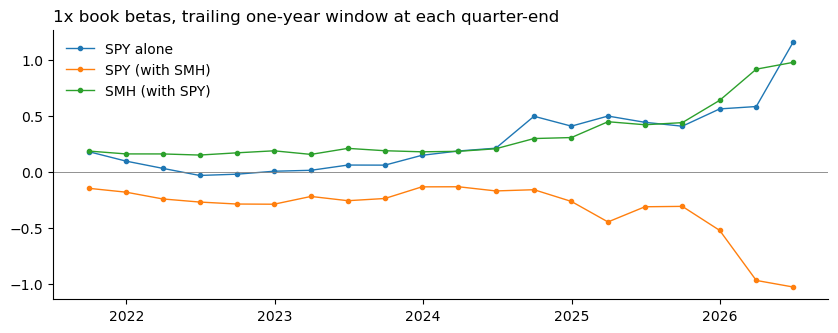

,SPY alone,SPY (with SMH),SMH (with SPY)
2021-09-30,0.18,-0.15,0.19
2021-12-31,0.10,-0.18,0.16
2022-03-31,0.03,-0.24,0.16
2022-06-30,-0.03,-0.27,0.15
2022-09-30,-0.02,-0.29,0.17
2022-12-30,0.01,-0.29,0.19
2023-03-31,0.01,-0.22,0.16
2023-06-30,0.06,-0.26,0.21
2023-09-29,0.06,-0.24,0.19
2023-12-29,0.15,-0.13,0.18


In [23]:
dates = excess.loc['2021-09':'2026-06'].index
quarter_ends = dates.to_series().groupby(dates.to_period('Q')).max()

rolling = {}
for qe in quarter_ends:
    window = excess.loc[:qe].iloc[-252:]                       # trailing one year, ending at the quarter-end
    book = portfolios.loc[window.index, '1x book']
    b1 = ols(book, window[['SPY']])[1]
    b2 = ols(book, window[['SPY', 'SMH']])[1]
    rolling[qe.date()] = {'SPY alone': b1['SPY'], 'SPY (with SMH)': b2['SPY'], 'SMH (with SPY)': b2['SMH']}
rolling = pd.DataFrame(rolling).T

rolling.plot(marker='o', ms=3, lw=1)
plt.axhline(0, color='grey', lw=0.6)
plt.title('1x book betas, trailing one-year window at each quarter-end', loc='left')
plt.legend(frameon=False); plt.show()
rolling.round(2)

**Answer 4.2.**

Throughout the 5-year window, the trailing one-year betas changed substantially even if the weights never changed. The SPY beta went from 0.18 to 1.16 from Sep 2021 to June 2026. Once controlling for SMH, the SPY beta went from -0.15 to -1.03, demonstrating that the rising beta was really just semiconductor exposure. The SMH beta rose from 0.19 to 0.98, and the long hardware short software trade became a levered bet on semis shorting the broader market.

## 4.3

> For each factor set in 4.1 and each window, report the average pairwise correlation of the residuals among the long names, among the short names, and across the sleeves, next to the same averages for the raw returns. Then, for the 2025-01-02 to 2026-06-30 window, compute the 1x book's variance three ways: from the sample covariance of the twelve names; from the factor model with a diagonal residual covariance; from the factor model with the full residual covariance. Do this for `SPY` alone and for `SPY` plus `SMH`.
> 
> - Convert each variance to a 4x one-day Normal 5% VaR.
> 
> After the factors are removed, how many dimensions of risk are left in this book? Which term does the diagonal drop, and how large is it as a share of the book's variance?
> 
> *Variance decomposition:* $\sigma^2_{\text{book}} = (B\boldsymbol{w})'\,\Sigma_f\,(B\boldsymbol{w}) + \boldsymbol{w}'\,\Sigma_\epsilon\,\boldsymbol{w}$. A factor risk model usually replaces $\Sigma_\epsilon$ with its diagonal; the sample covariance of the twelve names needs no such assumption.

In [24]:
def name_residuals(win, cols):
    return pd.DataFrame({n: ols(excess.loc[win, n], excess.loc[win, cols])[3] for n in NAMES})

def sleeve_corrs(df):
    c = df.corr()
    return {'long-long': avg_corr(c, LONGS, LONGS), 'short-short': avg_corr(c, SHORTS, SHORTS),
            'long-short': avg_corr(c, LONGS, SHORTS)}

rows = {}
for win_name, win in WINDOWS_4.items():
    rows[(win_name, 'raw excess returns')] = sleeve_corrs(excess.loc[win, NAMES])
    for fs_name, cols in FACTOR_SETS.items():
        rows[(win_name, f'residuals, {fs_name}')] = sleeve_corrs(name_residuals(win, cols))
pd.DataFrame(rows).T.round(2)

long-long  short-short  long-short
2021-24   raw excess returns         0.42         0.51        0.34
          residuals, SPY             0.19         0.25        0.03
          residuals, SPY + SMH       0.11         0.25       -0.01
2025-26H1 raw excess returns         0.55         0.50        0.11
          residuals, SPY             0.39         0.41       -0.12
          residuals, SPY + SMH       0.22         0.42       -0.04

In [25]:
# 1x book variance three ways, 2025-01-02 to 2026-06-30
w = w1[NAMES].values
X = excess.loc[RECENT]
var_rows = {'sample covariance': w @ X[NAMES].cov().values @ w}

for fs_name, cols in FACTOR_SETS.items():
    B = np.array([ols(X[n], X[cols])[1].values for n in NAMES])          # names x factors
    E = name_residuals(RECENT, cols)
    Bw = B.T @ w
    factor_part = Bw @ X[cols].cov().values @ Bw
    S_eps = E.cov().values
    var_rows[f'{fs_name}, diagonal residual'] = factor_part + w @ np.diag(np.diag(S_eps)) @ w
    var_rows[f'{fs_name}, full residual'] = factor_part + w @ S_eps @ w

table_4_3 = pd.Series(var_rows).to_frame('1x daily variance')
table_4_3['4x one-day Normal 5% VaR'] = -Z05 * 4 * np.sqrt(table_4_3['1x daily variance'])
table_4_3['share of sample variance'] = table_4_3['1x daily variance'] / var_rows['sample covariance']
table_4_3['dropped by diagonal'] = 1 - table_4_3['share of sample variance']
table_4_3['VaR understatement'] = 1 - table_4_3['4x one-day Normal 5% VaR'] / table_4_3.loc['sample covariance', '4x one-day Normal 5% VaR']
table_4_3.style.format({'1x daily variance': '{:.6f}', '4x one-day Normal 5% VaR': '{:.1%}',
                        'share of sample variance': '{:.0%}', 'dropped by diagonal': '{:.0%}',
                        'VaR understatement': '{:.0%}'})

,1x daily variance,4x one-day Normal 5% VaR,share of sample variance,dropped by diagonal,VaR understatement
sample covariance,0.000463,14.2%,100%,0%,0%
"SPY, diagonal residual",0.000182,8.9%,39%,61%,37%
"SPY, full residual",0.000463,14.2%,100%,-0%,0%
"SPY + SMH, diagonal residual",0.000311,11.6%,67%,33%,18%
"SPY + SMH, full residual",0.000463,14.2%,100%,0%,0%


In [26]:
# dimensions left after the factors: eigenvalues of the residual correlation matrix, 2025-26H1
eig = {}
for fs_name, cols in FACTOR_SETS.items():
    vals = np.sort(np.linalg.eigvalsh(name_residuals(RECENT, cols).corr().values))[::-1]
    eig[fs_name] = vals[:4] / vals.sum()
pd.DataFrame(eig, index=[f'eigenvalue {i}' for i in range(1, 5)]).style.format('{:.0%}')

,SPY,SPY + SMH
eigenvalue 1,34%,28%
eigenvalue 2,19%,18%
eigenvalue 3,9%,12%
eigenvalue 4,8%,9%


**Answer 4.3.**

After accounting for the factors, two dimensions of risk remain: a hardware theme and a software theme. Indeed, the close to zero correlation of the two-factor residuals across sleeves (-0.01 and -0.04 in 2021-24 and 2025-26H1, respectively) demonstrates the only thing software and hardware shared was the market, which is captured by the factors. Within the sleeves, though, hardware stocks and software stocks still move together more than what SPY and SMH explain (0.22 and 0.42 in 2025-26H1, respectively). Therefore, there are still two themes at play (hardware and software) not captured by SPY and SMH.

The diagonal drops the residual covariances, mainly within-sleeve, and their share of variance is 61% with SPY alone and 33% with SPY + SMH. Therefore, a standard diagonal factor model would put the 4x one-day 5% VaR at 8.9% (SPY) or 11.6% (SPY + SMH), lower than the 14.2% from the sample covariance, understating risk by 37% and 18%.

## 4.4

> Attribute the July 24 to 29 loss of the 4x book to its factor exposure and its residual, as sums of daily contributions, using betas from each window and both factor sets from 4.1.
> 
> - Report the systematic share under each of the four combinations.
> 
> Was the reversal a factor event or a residual event, and does the answer depend on what you call a factor?

In [27]:
total = book_4x.loc[REVERSAL].sum()          # sum of daily returns, so the parts add up exactly
rows = {}
for win_name, win in WINDOWS_4.items():
    for fs_name, cols in FACTOR_SETS.items():
        beta_4x = 4 * ols(portfolios.loc[win, '1x book'], excess.loc[win, cols])[1]
        systematic = (excess.loc[REVERSAL, cols] @ beta_4x).sum()
        rows[(f'{win_name} betas', fs_name)] = {'total (sum of daily)': total, 'systematic': systematic,
                                                'residual': total - systematic, 'systematic share': systematic / total}
print(f'four-day compounded loss: {four_day_loss:.1%}; sum of the four daily returns: {total:.1%}')
pd.DataFrame(rows).T.style.format('{:.1%}')

four-day compounded loss: 66.9%; sum of the four daily returns: -96.4%


**Answer 4.4.**

The reversal was mainly a residual event, but the extent to which it is depends on what we call a factor and which window we use to estimate the betas. Using 2021-24 betas, the systematic share of the sum of daily losses is just 0.5% under SPY alone and 11.5% under SPY + SMH, indicating that the vast majority of the losses are unexplained by the factors. With SPY alone the share stays small with 2025-26H1 betas too (3.5%), since SPY was roughly flat over the four days. Adding SMH with 2025-26H1 betas, however, raises it to 46%. By then the book was heavily exposed to semiconductors, which fell every day of the reversal. Whether we treat SMH as a factor therefore drastically changes the attribution, and the remaining residual is the hardware-vs-software spread.

---
# 5. Horizon and Survival

## 5.1

> Compute daily log excess returns of the 1x and 4x books. For 2021-01-04 to 2024-12-31, 2025-01-02 to 2026-06-30 and 2021-01-04 to 2026-06-30, report
> 
> - the annualized arithmetic mean, the annualized log mean, the annualized volatility, and the gap between the two means
> - for leverage 1x, 2x, 3x and 4x, the probability of underperforming cash over one month, one year and five years with the Barnstable formula, $\Pr\big[\texttt{r}_{t,t+h} < \texttt{r}^f_{t,t+h}\big] = \Phi\!\left(-\sqrt{h}\,\mu/\sigma\right)$, with $\mu$ and $\sigma$ the daily mean and standard deviation of the log excess return over cash
> - a plot of the probability against horizon for the four leverage levels on the 2021 to 2024 parameters
> 
> What sign does the 4x log mean take in each window, and what produces the gap? At each leverage, does a longer horizon raise or lower the probability? State in one sentence how this relates to the argument Barnstable's trustees made about stocks.
> 
> *Log returns:* $\texttt{r}_t = \ln(1+r_t)$. The book's return is already an excess return (zero-net weights), so its log return is the log excess return.

In [28]:
WINDOWS_5 = {'2021-24': PRE, '2025-26H1': RECENT, '2021-26H1': FULL}
HORIZONS = {'1 month': 21, '1 year': 252, '5 years': 1260}

def log_excess(L):
    return np.log1p(L * book_1x)

means = {}
for win_name, win in WINDOWS_5.items():
    for L in [1, 4]:
        arith = (L * book_1x.loc[win]).mean() * 252
        logr = log_excess(L).loc[win]
        means[(win_name, f'{L}x')] = {'arith. mean': arith, 'log mean': logr.mean() * 252,
                                      'ann. vol': logr.std() * np.sqrt(252), 'gap': arith - logr.mean() * 252}
pd.DataFrame(means).T.style.format('{:.1%}')

In [29]:
probs = {}
for win_name, win in WINDOWS_5.items():
    for L in [1, 2, 3, 4]:
        logr = log_excess(L).loc[win]
        probs[(win_name, f'{L}x')] = {h: norm.cdf(-np.sqrt(d) * logr.mean() / logr.std()) for h, d in HORIZONS.items()}
pd.DataFrame(probs).T.style.format('{:.1%}')

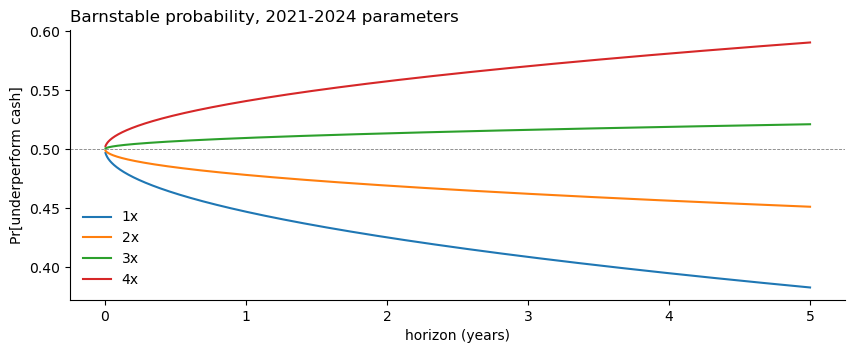

In [30]:
h = np.arange(1, 5 * 252 + 1)
for L in [1, 2, 3, 4]:
    logr = log_excess(L).loc[PRE]
    plt.plot(h / 252, norm.cdf(-np.sqrt(h) * logr.mean() / logr.std()), label=f'{L}x')
plt.axhline(0.5, color='grey', lw=0.6, ls='--')
plt.xlabel('horizon (years)'); plt.ylabel('Pr[underperform cash]')
plt.title('Barnstable probability, 2021-2024 parameters', loc='left')
plt.legend(frameon=False); plt.show()

**Answer 5.1.**

The 4x log mean is positive in each window aside from 2021-2024 (-6.41% despite a positive arithmetic mean of 13.35%). From 2025 to 2026H1, though, the strategy has a log mean return of 327.75%, pulling the full window (2021-2026) log mean to 84.04% despite the rough start. The gap between the arithmetic mean and the log mean is the volatility drag (approx. σ²/2), which scales with the square of leverage (1.24% at 1x vs 19.76% at 4x in 2021-2024), while the mean only scales linearly with leverage.

The probability of underperforming cash either increases or decreases depending on the sign of the log mean return, which in the 2021-24 window varies due to varying levels of leverage and thus volatility drag. With 1x and 2x leverage, the probability of underperforming falls with horizon. However, for 3x and 4x leverage, the probability rises and reaches 59% over 5 years at 4x leverage.

The Barnstable time diversification argument (mean grows with h, volatility with √h) only holds when the log mean is positive, which is not the case for the 3x and 4x levered book during the 2021-24 window, thus failing to decrease the probability of underperformance over time. In all other windows (2025-26H1 and 2021-26H1) the log mean return is positive at any leverage, and thus the probability of underperforming does fall over time.

## 5.2

> Simulate the probability that the 4x book suffers a maximum drawdown of at least 50% within one year and within five years, using the 2021-01-04 to 2026-06-30 parameters: once from a normal with the book's daily log mean and standard deviation, once by resampling the book's own daily returns. State the number of paths and random seed.
> 
> Compare the probabilities. Does the shape of the return distribution or the level of its volatility drive the answer? Explain how a drawdown from a running peak differs from a loss relative to initial wealth.
> 
> For each simulated path, cumulate log returns from initial wealth of one, track the running maximum including that initial value, and record the largest drawdown.

In [31]:
N_PATHS, SEED_5 = 10_000, 42
log_4x = np.log1p(book_4x.loc[FULL])

def path_probs(log_draws):
    log_wealth = np.hstack([np.zeros((len(log_draws), 1)), np.cumsum(log_draws, axis=1)])  # starts at wealth 1
    running_max = np.maximum.accumulate(log_wealth, axis=1)
    max_dd = 1 - np.exp((log_wealth - running_max).min(axis=1))
    return {'Pr[max drawdown >= 50%]': (max_dd >= 0.5).mean(),
            'Pr[wealth ever <= 50% of initial]': (np.exp(log_wealth.min(axis=1)) <= 0.5).mean()}

rng = np.random.default_rng(SEED_5)
table_5_2 = {}
for h_name, days in {'1 year': 252, '5 years': 1260}.items():
    table_5_2[('normal', h_name)] = path_probs(rng.normal(log_4x.mean(), log_4x.std(), size=(N_PATHS, days)))
    table_5_2[('bootstrap', h_name)] = path_probs(rng.choice(log_4x.values, size=(N_PATHS, days)))

print(f'{N_PATHS:,} paths per case, seed {SEED_5}; daily log mean {log_4x.mean():.4f}, daily log sd {log_4x.std():.4f}')
pd.DataFrame(table_5_2).T.style.format('{:.1%}')

10,000 paths per case, seed 42; daily log mean 0.0033, daily log sd 0.0569


,,Pr[max drawdown >= 50%],Pr[wealth ever <= 50% of initial]
normal,1 year,51.9%,16.2%
bootstrap,1 year,50.0%,16.2%
normal,5 years,98.6%,22.2%
bootstrap,5 years,98.0%,22.4%


**Answer 5.2.**

As demonstrated with the above Monte Carlo simulation (10,000 paths, seed 42) using normal and bootstrapped returns, the probability of a maximum drawdown of at least 50% in 1 year and 5 years is around 50% and 98%, respectively. This means that it is almost certain that the book will experience a fall of at least 50% in a five-year horizon. The normal and bootstrapped probabilities are nearly identical (51.9% vs 50.0% at 1 year, 98.6% vs 98.0% at 5 years), so it is the level of volatility, not the shape of the distribution, that drives the answer. 

This does not mean, though, that the probability of losing 50% of initial wealth over 5 years is 98%. The max drawdown is measured from the running peak, which is never below and usually well above the initial wealth, so a 50% fall from it typically still leaves more than half of the initial wealth. Therefore the probability that wealth ever falls below 50% of the initial value is only 22.4%.

## 5.3

> As of June 30, 2026, what gross exposure would you have recommended for this mandate, on what criterion, and estimated on which window? Give the number and the reasoning.

In [32]:
# candidate gross levels: volatility, log mean and bootstrap Pr[max drawdown >= 50% within one year], by window
rng = np.random.default_rng(SEED_5)
grid = {}
for win_name, win in WINDOWS_5.items():
    for g in [0.5, 1, 1.5, 2, 2.5, 3, 4]:
        logr = np.log1p(g / 4 * book_4x.loc[win])
        dd = path_probs(rng.choice(logr.values, size=(N_PATHS, 252)))['Pr[max drawdown >= 50%]']
        grid[(win_name, f'{g}x')] = {'ann. vol': logr.std() * np.sqrt(252), 'ann. log mean': logr.mean() * 252,
                                     'Pr[max DD >= 50%, 1 year]': dd}
pd.DataFrame(grid).T.style.format('{:.1%}')

**Answer 5.3.**

We recommend 2x gross. As a highly levered fund, we believe the criterion for risk management should not be avoiding a bad average return, but rather a deep drawdown. Therefore, leverage selection should be based on the question "what is the highest level of leverage such that the probability of a 50% drawdown within one year is below 5%?". We believe a 1-in-20 chance is a reasonable threshold for the risk appetite of an investor in a fund of these characteristics. The criterion also depends mainly on volatility, which is estimated far more precisely than the mean.

We estimate it on the full window (2021-26H1), all of which was available on June 30, but the choice of window does not change the answer. A 2x levered book sits below the threshold in all windows (4.2%, 4.1%, and 4.0% in the 2021-24, 2025-26H1, and 2021-26H1 samples respectively), while 2.5x sits above (12.1%, 14.7%, and 11.3% respectively).

Therefore, our recommendation holds in every window, including one with a losing regime and one with the theme playing out.

---
# 6. The Risk-Managed Mandate

The managed book keeps the twelve names, stays long the long sleeve and short the short sleeve, and never exceeds 4x gross. Every control uses only information available at the close before it acts. Every control is a rebalancing rule, and the constant-leverage comparators in 6.2 are daily-reset books at lower gross, so the comparison isolates timing from level.

## 6.1

> Before computing any Section 6 result, and before using any return after July 31, 2026, write a dated markdown cell that states
> 
> - two numeric pass-fail criteria, one about risk and one about return or the cost of control
> - the control or controls you will test, chosen from a volatility target, a VaR or CVaR limit, a drawdown rule, a factor hedge, a sleeve or position cap, or a combination
> - every parameter
> 
> One well-motivated control is sufficient. You may use the risk measure or hedge developed in Section 7 as part of it; those questions still require their own analysis. Keep the original declaration. Record any revision in a second dated cell.

**October 28th, 2026.**

We want to design a control which targets an annualized volatility of 40% at all times, slightly lower than the 45% full sample volatility of the 2x gross book chosen in part 5.3 leaving a small margin. Furthermore, our control should not allow our gross exposure to exceed 4x even in calm times.

For day $t$, gross exposure is $g_t = \min\big(4,\; 4 \times 0.40 / \hat\sigma^{\text{ann}}_{t}\big)$, where $\hat\sigma^{\text{ann}}_t = \sqrt{252}\,\sigma_t$ is the EWMA forecast of the 4x book made at the close of $t-1$ (as in 3.1).

The parameters are as follows:
- Target annualized volatility: 40%
- Cap: 4x gross
- Floor: no floor
- λ (for EWMA as in 3.1): 0.94
- All weights are scaled by $g_t/4$ such that the net exposure is always 0
- Rebalanced at every close

The comparator will have a constant gross exposure equal to the managed book's average gross over the report window.

**Criteria**:

1. Risk: The realized annualized volatility of the managed book does not exceed 50% (1.25 × target)
2. Cost: The managed Sharpe ratio is no more than 0.5 below the constant-leverage comparator's Sharpe

## 6.2

> Implement the declared controls on the design window. Over the report window, 2025-01-02 to 2026-07-31, for the managed book, the unmanaged 4x book, the 1x book, and a constant-leverage comparator whose gross exposure equals the managed book's average gross over the report window, report
> 
> - gross exposure through time and the dates on which the controls bound
> - cumulative return to July 23, the July 24 to 29 return, and cumulative return to July 31
> - annualized volatility, Sharpe ratio and maximum drawdown
> - average gross exposure, and the gross exposure set at the July 23 close (for July 24)
> 
> Compare each control with constant exposure at the same average gross leverage to distinguish timing from position size. State what each control cost or earned before the reversal and during it, against the unmanaged book and against its comparator, and whether an investor reviewing the managed book in April 2026 would have kept it.

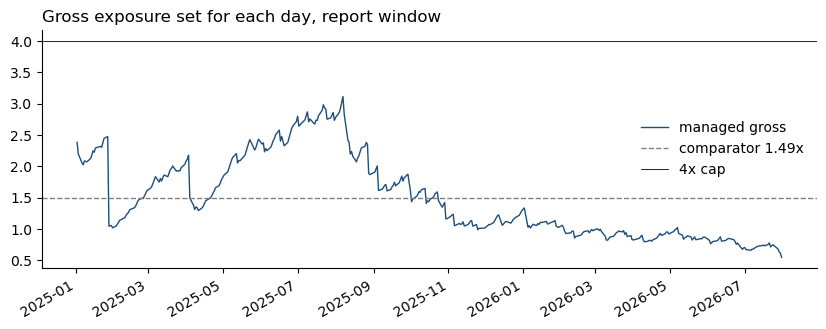

volatility target bound (gross < 4x) on 395 of 395 days; gross ranged 0.55x to 3.11x


,cum. return to Jul 23,Jul 24-29,cum. return to Jul 31,ann. vol,Sharpe,max drawdown,avg gross,gross set Jul 23 (for Jul 24)
managed,+540.1%,-15.6%,+468.5%,45.5%,2.67,-30.1%,1.49x,0.75x
unmanaged 4x,+8526.7%,-66.9%,+3712.8%,148.3%,2.33,-82.3%,4.00x,4.00x
1x book,+310.4%,-22.0%,+247.5%,37.1%,2.33,-30.2%,1.00x,1.00x
constant 1.49x,+661.0%,-31.3%,+488.9%,55.2%,2.33,-42.3%,1.49x,1.49x


In [33]:
TARGET_VOL, MAX_GROSS = 0.40, 4.0
RISK_LIMIT, SHARPE_TOLERANCE = 0.50, 0.5

def managed_gross(sigma_daily):
    """Gross for day t from the EWMA forecast made at the close of t-1."""
    return np.minimum(MAX_GROSS, MAX_GROSS * TARGET_VOL / (sigma_daily * np.sqrt(252)))

def max_drawdown(r):
    wealth = (1 + r).cumprod()
    return (wealth / np.maximum(wealth.cummax(), 1) - 1).min()     # peak includes the starting value

gross = managed_gross(fc['sigma']).loc[REPORT]
avg_gross = gross.mean()
r4 = book_4x.loc[REPORT]
COMP = f'constant {avg_gross:.2f}x'

books = {'managed': gross / 4 * r4, 'unmanaged 4x': r4, '1x book': r4 / 4, COMP: avg_gross / 4 * r4}
gross_of = {'managed': gross, 'unmanaged 4x': 4.0, '1x book': 1.0, COMP: avg_gross}

table_6_2 = {}
for name, r in books.items():
    g = gross_of[name] * pd.Series(1.0, index=r.index)
    table_6_2[name] = {
        'cum. return to Jul 23': (1 + r.loc[:'2026-07-23']).prod() - 1,
        'Jul 24-29': (1 + r.loc[REVERSAL]).prod() - 1,
        'cum. return to Jul 31': (1 + r).prod() - 1,
        'ann. vol': r.std() * np.sqrt(252),
        'Sharpe': r.mean() / r.std() * np.sqrt(252),
        'max drawdown': max_drawdown(r),
        'avg gross': g.mean(),
        'gross set Jul 23 (for Jul 24)': g.loc['2026-07-24'],
    }
table_6_2 = pd.DataFrame(table_6_2).T

bound = gross < MAX_GROSS
gross.plot(color='#1f4e79', lw=1, label='managed gross')
plt.axhline(avg_gross, color='grey', lw=1, ls='--', label=f'comparator {avg_gross:.2f}x')
plt.axhline(MAX_GROSS, color='black', lw=0.6, label='4x cap')
plt.title('Gross exposure set for each day, report window', loc='left'); plt.xlabel(''); plt.legend(frameon=False); plt.show()
print(f'volatility target bound (gross < 4x) on {bound.sum()} of {len(bound)} days; '
      f'gross ranged {gross.min():.2f}x to {gross.max():.2f}x')

table_6_2.style.format('{:+.1%}').format('{:.1%}', subset=['ann. vol', 'max drawdown']).format('{:.2f}', subset=['Sharpe']).format('{:.2f}x', subset=['avg gross', 'gross set Jul 23 (for Jul 24)'])

In [34]:
# what the managed book looked like to an investor reviewing it at the end of April 2026
april = {}
for name, r in books.items():
    r = r.loc[:'2026-04-30']
    april[name] = {'cum. return': (1 + r).prod() - 1, 'ann. vol': r.std() * np.sqrt(252),
                   'Sharpe': r.mean() / r.std() * np.sqrt(252), 'max drawdown': max_drawdown(r)}
pd.DataFrame(april).T.style.format('{:+.1%}').format('{:.1%}', subset=['ann. vol', 'max drawdown']).format('{:.2f}', subset=['Sharpe'])

,cum. return,ann. vol,Sharpe,max drawdown
managed,+489.8%,45.3%,3.22,-30.1%
unmanaged 4x,+9295.0%,124.2%,3.42,-47.8%
1x book,+279.7%,31.0%,3.42,-12.1%
constant 1.49x,+593.9%,46.2%,3.42,-18.1%


In [35]:
def criteria(tab):
    vol = tab.loc['managed', 'ann. vol']
    gap = tab.loc['managed', 'Sharpe'] - tab.loc[COMP, 'Sharpe']
    return {f'risk: managed vol <= {RISK_LIMIT:.0%}': f'{vol:.1%} -> ' + ('PASS' if vol <= RISK_LIMIT else 'FAIL'),
            f'cost: Sharpe gap to comparator >= -{SHARPE_TOLERANCE}': f'{gap:+.2f} -> ' + ('PASS' if gap >= -SHARPE_TOLERANCE else 'FAIL')}

pd.Series(criteria(table_6_2)).to_frame('report window')

,report window
risk: managed vol <= 50%,45.5% -> PASS
cost: Sharpe gap to comparator >= -0.5,+0.34 -> PASS


**Answer 6.2.**

_Full period:_

Compared with the constant leverage book with 1.49x leverage, the managed book had a lower return to July 31st of +469% vs +489%. This delta is due to the timing of the leverage: the managed book may have delevered in a high volatility regime when the strategy performed well. However, the managed book's realized volatility was lower than that of the constant book (45.5% vs 55.2%) and thus achieved a higher Sharpe (2.67 vs 2.33).

_Pre-reversal:_

Zooming into the period before the reversal, we see the difference in returns is higher: +540% (managed) vs +661% (constant). As the expected volatility increased, the managed book delevered, missing some of the levered gains leading up to the reversal. As expected, the managed book also underperformed the 4x levered book (+540% vs +8,527%), although most of this is due to gross exposure, not just timing.

_Reversal:_

During the reversal, though, the managed book performed as it was designed to, losing only 15.6% vs 31.3% for the constant book. In a high volatility, reversal environment, deleveraging protected the book from large losses. These gains from timing are even higher if we compare them to the losses of the 4x book (-66.9%).

_April 2026:_

From the point of view of an investor at the end of April 2026, however, the managed book looks worse in all metrics: its cumulative return (+489.8%) is lower than that of the constant book (+593.9%) and even though its volatility is slightly lower (45.3% vs 46.2%), its Sharpe is 0.20 lower (3.22 vs 3.42). Furthermore, its max drawdown is also much larger (-30.1% vs -18.1%). An April reviewer, thus, might have discarded the control as, at that point in time, it did not seem to lead to better risk-adjusted returns.

_Criteria:_
The control passes both criteria. Its realized volatility of 45.5% is below the 50% limit, and its Sharpe ratio is 0.34 higher than that of the constant leverage book (a gain rather than a cost), well within the −0.5 tolerance. Even at the end of April 2026, when the control looked worst, its Sharpe was only 0.20 below the comparator's, which would also have passed.  

## 6.3

> Run the same controls, unchanged, from August 3, 2026 to the end of the file, with the same comparators.
> 
> - Report the same statistics plus the worst day.
> - Apply the criteria declared in 6.1: pass or fail, by your own test.
> 
> If the design window and the holdout disagree about a control, say which you believe and why.

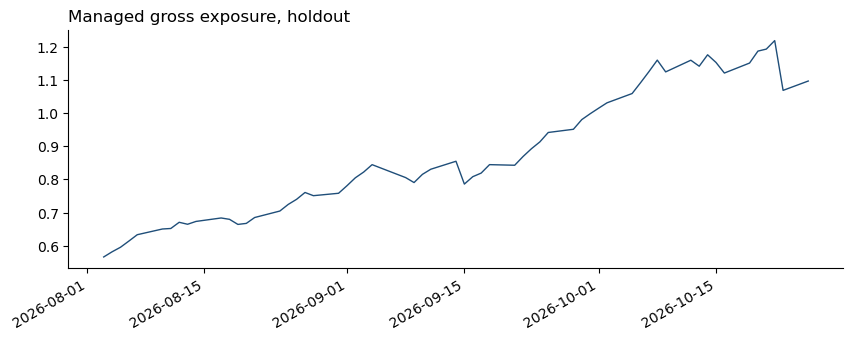

,cum. return,ann. vol,Sharpe,max drawdown,worst day,avg gross
managed,-12.5%,32.7%,-1.56,-21.0%,-6.2%,0.87x
unmanaged 4x,-45.0%,150.5%,-0.89,-60.2%,-23.7%,4.00x
1x book,-9.2%,37.6%,-0.89,-18.1%,-5.9%,1.00x
constant 1.49x,-14.5%,56.0%,-0.89,-26.0%,-8.8%,1.49x


,report window,holdout
risk: managed vol <= 50%,45.5% -> PASS,32.7% -> PASS
cost: Sharpe gap to comparator >= -0.5,+0.34 -> PASS,-0.66 -> FAIL


In [36]:
# holdout opened here for the first time; the EWMA runs on the full series, so it only ever uses past returns
book_4x_all = returns_all[NAMES] @ weights
gross_hold = managed_gross(ewma_vol(book_4x_all)).loc['2026-08-03':]
r_hold = book_4x_all.loc['2026-08-03':]

books_hold = {'managed': gross_hold / 4 * r_hold, 'unmanaged 4x': r_hold, '1x book': r_hold / 4, COMP: avg_gross / 4 * r_hold}
gross_hold_of = gross_of | {'managed': gross_hold}

table_6_3 = {}
for name, r in books_hold.items():
    g = gross_hold_of[name] * pd.Series(1.0, index=r.index)
    table_6_3[name] = {'cum. return': (1 + r).prod() - 1, 'ann. vol': r.std() * np.sqrt(252),
                       'Sharpe': r.mean() / r.std() * np.sqrt(252), 'max drawdown': max_drawdown(r),
                       'worst day': r.min(), 'avg gross': g.mean()}
table_6_3 = pd.DataFrame(table_6_3).T

gross_hold.plot(color='#1f4e79', lw=1)
plt.title('Managed gross exposure, holdout', loc='left'); plt.xlabel(''); plt.show()

display(table_6_3.style.format('{:+.1%}').format('{:.1%}', subset=['ann. vol', 'max drawdown', 'worst day']).format('{:.2f}', subset=['Sharpe']).format('{:.2f}x', subset=['avg gross']))
pd.DataFrame({'report window': criteria(table_6_2), 'holdout': criteria(table_6_3)})

**Answer 6.3.**

All books had a negative cumulative return during the holdout period, but the managed book's Sharpe ratio was much lower than that of the constant-leverage books (-1.56 vs. -0.89).

While the volatility criterion of the managed book passed (32.7% < 50%; worst day -6.2% vs -8.8% for the constant book and -23.7% for the unmanaged book), its Sharpe ratio is 0.66 points below the comparator's, which breaches the -0.5 cost rule we set. This is because while it kept the volatility low versus the constant 1.49x levered book (32.7% vs 56.0%), its return fell almost as much as the constant book's (-12.5% vs. -14.5%), meaning the volatility targeting rule did not improve risk-adjusted returns.

The design window and the holdout window disagree on the cost of the strategy (+0.34 vs −0.66 units of Sharpe). Even though the design window is in-sample (since the volatility target reference was the full period's volatility 2021-2026H1), we believe it is still the best reference because of what the control is designed to do: mitigate losses in significant reversals such as in July. While it is true that out of sample it did not perform as expected, the out-of-sample regime was not a sudden reversal but rather months of consistent underperformance, which is something we can tolerate more as risk managers than a sudden reversal such as the July one. Furthermore, with only three months of data, the standard error of the holdout Sharpe is c. 2, so the -0.66 gap is not statistically significant.

---
# 7. Reporting and Recommendation

Choose the additional risk measure, hedge specification, dashboard item, and final recommendation. Support each choice with the relevant comparison; the required analysis can justify different decisions.

## 7.1

> Propose one risk number a risk manager should have reported beside the one-day 5% VaR for this book, built from the same inputs. Define it, compute it daily through the design window, and report the forecast made at the June 22, July 1 and July 23, 2026 closes (for the following day). Justify the choice in course terms.

*Choice implemented below:* five-day 1% CVaR by filtered historical simulation, using a 504-day standardization window, scaled from one day by $\sqrt{5}$.

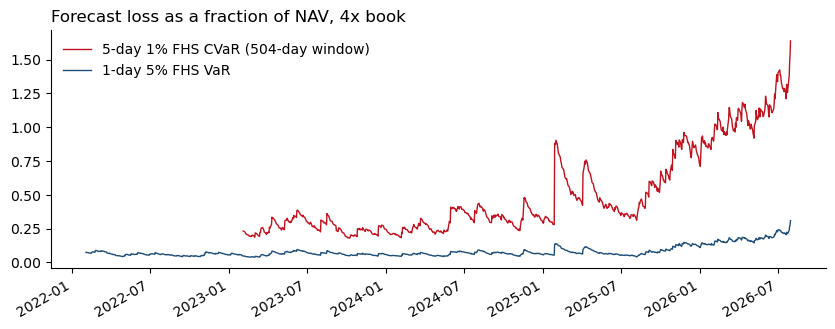

,for day,1-day 5% FHS VaR,5-day 1% FHS CVaR
2026-06-22,2026-06-23,19.4%,117.4%
2026-07-01,2026-07-02,24.2%,140.1%
2026-07-23,2026-07-24,21.3%,125.7%


In [37]:
STRESS_ALPHA, STRESS_DAYS, STRESS_WINDOW = 0.01, 5, 504

z_book = (book_4x / fc['sigma']).values
stress = pd.Series(np.nan, index=book_4x.index)
for t in range(INIT_DAYS + STRESS_WINDOW, len(book_4x)):
    _, z_cvar = var_cvar(z_book[t - STRESS_WINDOW:t], STRESS_ALPHA)
    stress.iloc[t] = z_cvar * fc['sigma'].iloc[t] * np.sqrt(STRESS_DAYS)

stress.plot(color='#c1121f', lw=1, label='5-day 1% FHS CVaR (504-day window)')
fc['FHS VaR'].plot(color='#1f4e79', lw=1, label='1-day 5% FHS VaR')
plt.title('Forecast loss as a fraction of NAV, 4x book', loc='left'); plt.xlabel(''); plt.legend(frameon=False); plt.show()

next_day = lambda d: book_4x.index[book_4x.index.get_loc(pd.Timestamp(d)) + 1]
pd.DataFrame({d: {'for day': next_day(d).date(), '1-day 5% FHS VaR': f'{fc.loc[next_day(d), "FHS VaR"]:.1%}',
                  '5-day 1% FHS CVaR': f'{stress.loc[next_day(d)]:.1%}'}
              for d in ['2026-06-22', '2026-07-01', '2026-07-23']}).T

In [43]:
print('5-day stress CVaR first above 100% of NAV:', (stress > 1).idxmax().date())

5-day stress CVaR first above 100% of NAV: 2026-02-05


**Answer 7.1.**

For our alternative risk measure we chose a 5-day 1% CVaR using the filtered historical simulation methodology on a 504-day window. It is calculated by taking the 504-day window of standardized returns, averaging the worst 1% of outcomes, and multiplying that by today’s EWMA estimated volatility, scaling by √5 to get the 5-day CVaR.

The reason we chose CVaR is because it measures losses beyond VaR and captures the long tail which we are trying to avoid at all cost running a strategy like this. Furthermore, given that the type of losses that can wipe out a fund sit deep in the tail (at the worst 1% of outcomes), we chose a 1% CVaR instead of the usual 5%. We also chose a 5-day CVaR and not just a one-day CVaR because the type of reversal that leads to a fund blowing up usually comes in a streak of bad days, not just one day. We chose FHS because it is the best calibrated methodology according to our analysis in 3.2 and it keeps the true fat tails scaled at the current volatility. Finally, we chose a 504-day window to keep the January 2025 (DeepSeek) crash within the window. Since the √5 scaling assumes independent days, which failed during the reversal (3.3), the measure is if anything understated and thus should be taken with even more caution by the risk manager.

Computing these metrics gives us a 1-day 5% VaR of 19.4%/24.2%/21.3% but a 5-day 1% CVaR of 117.4%/140.1%/125.7% at the June 22, July 1 and July 23 closes. The one-day VaR numbers could have convinced a risk manager that a c. 20% fall was survivable. However, they do not capture the deep left-tail losses and the fact that they came in a streak. On the other hand, our 5-day 1% CVaR would have shown that in the worst 1% of weeks the expected loss exceeds the fund’s entire NAV, which it did from February 5, 2026 onward, a sufficient signal to delever and avoid this outcome. 


## 7.2

> Design a hedge overlay for the 4x book using trailing-window betas to one or more of `SPY`, `SMH` and the sector ETFs, refreshed at a frequency you choose.
> 
> - Report the overlay positions as multiples of NAV.
> - Report the hedged book's annualized volatility, Sharpe ratio and July 24 to 29 return over the report window, against the unhedged book.
> 
> Recommend for or against running it. Include the position sizes in the recommendation.

*Choice implemented below:* at each month-end close, regress the 4x book on `SPY` and `SMH` excess returns over the trailing 126 days and hold $-\beta$ in each ETF (as a multiple of NAV) for the following month.

In [38]:
HEDGE_WINDOW, HEDGE_FACTORS = 126, ['SPY', 'SMH']

all_month_ends = excess.index.to_series().groupby(excess.index.to_period('M')).max()
all_month_ends = all_month_ends[all_month_ends >= '2024-12-01']

positions = {}
for me in all_month_ends:
    window = excess.loc[:me].iloc[-HEDGE_WINDOW:]
    positions[me] = -ols(book_4x.loc[window.index], window[HEDGE_FACTORS])[1]
positions = pd.DataFrame(positions).T

# a position set at a month-end close is held from the next day
daily_hedge = positions.reindex(excess.index, method='ffill').shift(1).loc[REPORT]
hedged = book_4x.loc[REPORT] + (daily_hedge * excess.loc[REPORT, HEDGE_FACTORS]).sum(axis=1)

def hedge_stats(r):
    return {'ann. vol': f'{r.std() * np.sqrt(252):.1%}', 'Sharpe': round(r.mean() / r.std() * np.sqrt(252), 2),
            'Jul 24-29': f'{(1 + r.loc[REVERSAL]).prod() - 1:.1%}'}

display(pd.DataFrame({'unhedged 4x': hedge_stats(book_4x.loc[REPORT]), 'hedged 4x': hedge_stats(hedged)}).T)
print('overlay positions set at each month-end close (x NAV)')
shown = positions.loc['2024-12-31':'2026-06-30']
shown.set_axis(shown.index.date).rename(columns=lambda c: f'{c} (x NAV)').round(2)

,ann. vol,Sharpe,Jul 24-29
unhedged 4x,148.3%,2.33,-66.9%
hedged 4x,104.6%,1.98,-34.7%


overlay positions set at each month-end close (x NAV)


,SPY (x NAV),SMH (x NAV)
2024-12-31,0.89,-1.29
2025-01-31,2.16,-2.02
2025-02-28,2.10,-1.98
2025-03-31,1.93,-1.92
2025-04-30,1.58,-1.94
2025-05-30,2.00,-2.24
2025-06-30,2.15,-2.34
2025-07-31,0.75,-1.44
2025-08-29,0.93,-1.56
2025-09-30,0.70,-1.52


**Answer 7.2.**

We advise against implementing the factor hedge. While it is true that the factor hedge almost halved the reversal loss (−34.7% vs −66.9%), the positions needed to maintain the hedge are huge by the time the reversal occurs (+6.91x SPY and −4.67x SMH, set at the June 30 close and in force during the reversal), adding about 11.6x NAV of ETF gross exposure on top of the book's 4x. Furthermore, the betas are too unstable, leading to the hedge itself adding estimation error. On top of that, the volatility only falls to 104.6% (from 148.3%), meaning that most of the risk comes from the residual spread, as discussed in part 4.3. As a result of the hedge, the Sharpe also falls from 2.33 to 1.98, meaning that it doesn't improve risk-adjusted returns. Finally, and most importantly, hedging the SMH exposure in a way distorts the thesis the fund is making: removing semis exposure is removing arguably the most important part of the AI hardware industry.

A simpler alternative was the one discussed in part 6, which is simply cutting the gross exposure to reduce volatility while not having to manage such a sizeable hedge.

## 7.3

> Build the one-page view a risk manager should have had at the July 23, 2026 close, from data through that date only: a small table or a few figures covering
> 
> - the volatility level and its history
> - the VaR and CVaR forecast made at that close (for the following day)
> - the drawdown from peak, the factor exposures, and one item of your choice
> 
> Produce the same page for the June 22, 2026 close. For each date, say in three or four sentences what the page showed and what action it supported.

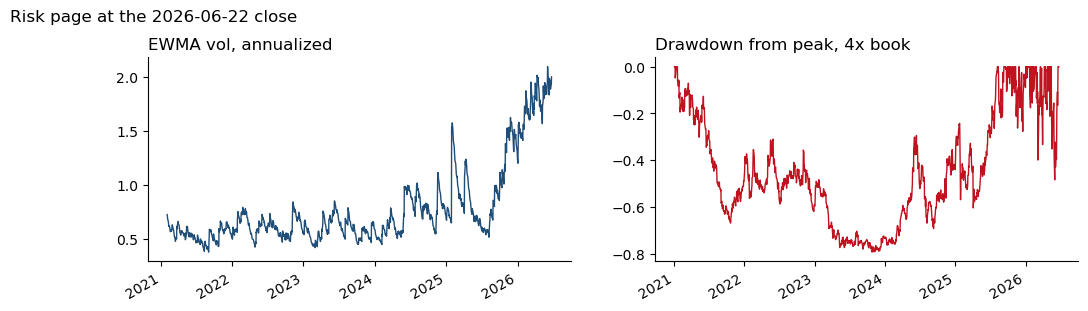

,2026-06-22 close
"EWMA vol, annualized (for next day)",200%
percentile of vol history,100%
HS VaR / CVaR,15.0% / 18.4%
EWMA VaR / CVaR,20.7% / 26.0%
FHS VaR / CVaR,19.4% / 24.9%
drawdown from peak,0.0%
"factor exposure, SPY (x NAV, 126d)",-6.43
"factor exposure, SMH (x NAV, 126d)",4.47
5-day 1% stress CVaR (7.1),117%


In [39]:
def risk_page(date):
    d = pd.Timestamp(date)
    nxt = next_day(date)                                  # forecasts made at this close are indexed by the next day
    sigma_hist = ewma_ann.loc[:nxt].dropna()
    wealth = (1 + book_4x.loc[:d]).cumprod()
    drawdown = wealth / wealth.cummax() - 1
    window = excess.loc[:d].iloc[-HEDGE_WINDOW:]
    betas = ols(book_4x.loc[window.index], window[HEDGE_FACTORS])[1]

    table = pd.Series({
        'EWMA vol, annualized (for next day)': f'{sigma_hist.iloc[-1]:.0%}',
        'percentile of vol history': f'{(sigma_hist.iloc[:-1] < sigma_hist.iloc[-1]).mean():.0%}',
        **{f'{m} VaR / CVaR': f'{fc.loc[nxt, f"{m} VaR"]:.1%} / {fc.loc[nxt, f"{m} CVaR"]:.1%}' for m in METHODS},
        'drawdown from peak': f'{drawdown.iloc[-1]:.1%}',
        'factor exposure, SPY (x NAV, 126d)': f'{betas["SPY"]:.2f}',
        'factor exposure, SMH (x NAV, 126d)': f'{betas["SMH"]:.2f}',
        '5-day 1% stress CVaR (7.1)': f'{stress.loc[nxt]:.0%}',
    }).to_frame(f'{d.date()} close')

    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    sigma_hist.plot(ax=axes[0], color='#1f4e79', lw=1); axes[0].set_title('EWMA vol, annualized', loc='left')
    drawdown.plot(ax=axes[1], color='#c1121f', lw=1); axes[1].set_title('Drawdown from peak, 4x book', loc='left')
    for ax in axes: ax.set_xlabel('')
    fig.suptitle(f'Risk page at the {d.date()} close', x=0.01, y=1.04, ha='left', fontsize=12)
    plt.show()
    display(table)

risk_page('2026-06-22')

**Answer 7.3: 2026-06-22** 

At the 2026-06-22 close, the book was at its peak, but all the risk metrics were sounding the alarms. The estimated EWMA annualized volatility was 200% for the next day, higher than on any previous day. Likewise, the one-day FHS VaR/CVaR (best-calibrated) were 19.4%/24.9% and the 5-day 1% stress CVaR was 117%, with the book +4.47x NAV in SMH and −6.43x NAV in SPY. This meant that a bad week could exceed the NAV, that the drawdown was hiding the risk, and that the book was a concentrated bet on semis. The page supported cutting gross immediately, at the peak, to about 0.8x (the 40% volatility target at 200% volatility).

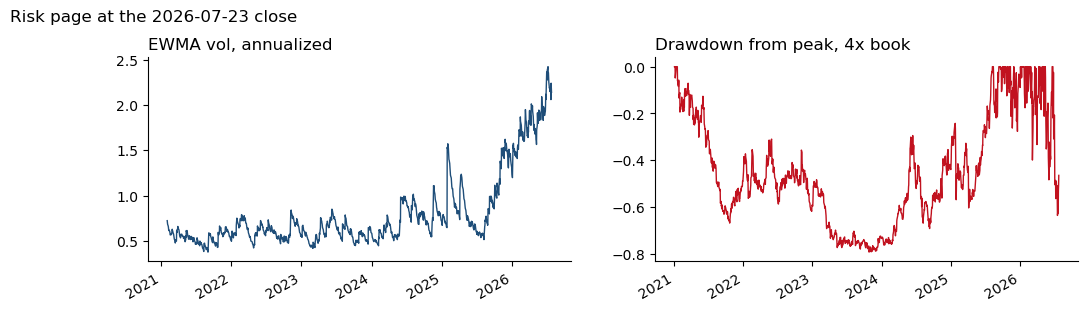

,2026-07-23 close
"EWMA vol, annualized (for next day)",214%
percentile of vol history,99%
HS VaR / CVaR,16.6% / 20.9%
EWMA VaR / CVaR,22.2% / 27.8%
FHS VaR / CVaR,21.3% / 27.3%
drawdown from peak,-46.5%
"factor exposure, SPY (x NAV, 126d)",-6.51
"factor exposure, SMH (x NAV, 126d)",4.60
5-day 1% stress CVaR (7.1),126%


In [40]:
risk_page('2026-07-23')

**Answer 7.3: 2026-07-23**

At the 2026-07-23 close, the book was 46.5% below its peak, with an estimated next-day EWMA annualized volatility of 214%, a one-day FHS VaR/CVaR (best-calibrated) of 21.3% / 27.3% and a 5-day 1% stress CVaR of 126%. The drawdown did not hide the risk anymore, and the volatility and risk of further losses were even higher than at the peak. The book was now +4.60x NAV in SMH and −6.51x NAV in SPY, a slightly larger semis bet than at the peak. While the best time to delever was June, the second best time is this instant, taking gross exposure to about 0.75x (the 40% volatility target at 214% volatility).

## 7.4

> In half a page, state the gross exposure and controls under which you would run this mandate going forward, drawing on the design results and the holdout verdict in 6.3, what the mandate's investors give up for them, and one observable result over the next year that would make you reverse the decision.

**Answer 7.4.**

_Gross exposure and controls:_

Going forward we would run the volatility target as declared in 6.1 (40% annualized, EWMA λ = 0.94, rebalanced daily), but we would adjust the gross cap from 4x to 2x, as that is the leverage level supported by part 5.3. Furthermore, we would call a risk-committee review whenever the 5-day 1% stress CVaR from 7.1 exceeds 50% of NAV. We would not run the beta overlay for the reasons discussed in 7.2.

_Rationale:_

We choose this control on the basis of risk. The control kept volatility at or below target in both the design and the holdout window (45.5% and 32.7%) and halved the reversal loss against the comparator with the same gross leverage (−15.6% vs −31.3%). Even though out of sample it failed the cost criterion (Sharpe gap −0.66), we believe that with three months of data that gap is within noise as we mentioned in 6.3. The 2x cap we incorporate now would have bound in the design window (whereas the 4x cap did not), when gross rose up to 3.11x. However, it would not have bound in the holdout (peak 1.22x). This is exactly what it was designed for, a limit for calm periods such that a sudden reversal does not lead to a sharp (and perhaps too slow) delevering, as on January 27, 2025 (DeepSeek), when the control entered the day at 2.47x gross and lost 22% of NAV before it could react.

_Tradeoff:_

By incorporating this control, investors give up most of the upside of a leveraged trend (+469% instead of +3,713% over the report window). Furthermore, they must accept periods when the control trails a constant-leverage book (such as April 2026 and the holdout). In exchange, however, the book should not lose 80% of NAV, as the unmanaged book did.

_What would reverse our decision:_

We would reverse the decision if the managed book's realized volatility over any three-month window in the next year exceeds 50% (1.25 × target), which would mean the EWMA forecast is not tracking this book. If this happens, we would then simply run a fixed 1x gross.

---
## Use of AI

We used Claude (Anthropic) throughout the project. It was most helpful for writing and debugging the code. We verified its outputs by reading the codechecking identities in the results, comparing numbers against independently written group notebooks, and matching formulas to the brief and the course notes.

---
